In [ ]:
from itertools import permutations
import time

def conflicts(board):
  """board[c] = row of the queen in column c. Count attacking pairs."""
  n = len(board); bad = 0
  for i in range(n):
    for j in range(i+1, n):
      same_row  = board[i] == board[j]
      same_diag = abs(board[i]-board[j]) == abs(i-j)
      if same_row or same_diag:
        bad += 1
  return bad

t0 = time.perf_counter()
sols = [p for p in permutations(range(8)) if conflicts(p) == 0]
print(f'{len(sols)} solutions in {time.perf_counter()-t0:.3f} s')
print('first:', sols)

92 solutions in 0.523 s
first: [(0, 4, 7, 5, 2, 6, 1, 3), (0, 5, 7, 2, 6, 3, 1, 4), (0, 6, 3, 5, 7, 1, 4, 2), (0, 6, 4, 7, 1, 3, 5, 2), (1, 3, 5, 7, 2, 0, 6, 4), (1, 4, 6, 0, 2, 7, 5, 3), (1, 4, 6, 3, 0, 7, 5, 2), (1, 5, 0, 6, 3, 7, 2, 4), (1, 5, 7, 2, 0, 3, 6, 4), (1, 6, 2, 5, 7, 4, 0, 3), (1, 6, 4, 7, 0, 3, 5, 2), (1, 7, 5, 0, 2, 4, 6, 3), (2, 0, 6, 4, 7, 1, 3, 5), (2, 4, 1, 7, 0, 6, 3, 5), (2, 4, 1, 7, 5, 3, 6, 0), (2, 4, 6, 0, 3, 1, 7, 5), (2, 4, 7, 3, 0, 6, 1, 5), (2, 5, 1, 4, 7, 0, 6, 3), (2, 5, 1, 6, 0, 3, 7, 4), (2, 5, 1, 6, 4, 0, 7, 3), (2, 5, 3, 0, 7, 4, 6, 1), (2, 5, 3, 1, 7, 4, 6, 0), (2, 5, 7, 0, 3, 6, 4, 1), (2, 5, 7, 0, 4, 6, 1, 3), (2, 5, 7, 1, 3, 0, 6, 4), (2, 6, 1, 7, 4, 0, 3, 5), (2, 6, 1, 7, 5, 3, 0, 4), (2, 7, 3, 6, 0, 5, 1, 4), (3, 0, 4, 7, 1, 6, 2, 5), (3, 0, 4, 7, 5, 2, 6, 1), (3, 1, 4, 7, 5, 0, 2, 6), (3, 1, 6, 2, 5, 7, 0, 4), (3, 1, 6, 2, 5, 7, 4, 0), (3, 1, 6, 4, 0, 7, 5, 2), (3, 1, 7, 4, 6, 0, 2, 5), (3, 1, 7, 5, 0, 2, 4, 6), (3, 5, 0, 4, 1, 7, 2, 6), (3, 5,

In [ ]:
def is_safe(board, col, row):
    """Can a queen sit at (row, col), given columns 0..col-1 are placed?"""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

def solve(n=8):
    sols, nodes = [], [0]
    def place(board, col):
        if col == n:
            sols.append(tuple(board))
            return
        for row in range(n):
            nodes[0] += 1
            if is_safe(board, col, row):
                board[col] = row       # Place queen
                place(board, col + 1)  # Move to next column
                board[col] = -1        # Undo: backtracking
    place([-1] * n, 0)
    return sols, nodes[0]

sols, nodes = solve(8)
print(len(sols), 'solutions,', nodes, 'nodes visited')

92 solutions, 15720 nodes visited


In [ ]:
import time
print(f"{'n':>3} {'solutions':>10} {'nodes':>10} {'backtrack':>11} {'generate':>11}")
for n in range(4, 11):
  t0 = time.perf_counter(); s, nd = solve(n); tb = time.perf_counter()-t0
  t0 = time.perf_counter()
  _ = [p for p in permutations(range(n)) if conflicts(p) == 0]
  tg = time.perf_counter()-t0
  print(f'{n:>3} {len(s):>10} {nd:>10} {tb:>10.4f}s {tg:>10.4f}s')

  n  solutions      nodes   backtrack    generate
  4          2         60     0.0000s     0.0001s
  5         10        220     0.0001s     0.0010s
  6          4        894     0.0005s     0.0023s
  7         40       3584     0.0022s     0.0246s
  8         92      15720     0.0128s     0.3566s
  9        352      72378     0.0610s     3.3949s
 10        724     348150     0.4554s    36.0056s



Displaying first 3 solutions for N=8 with matplotlib:


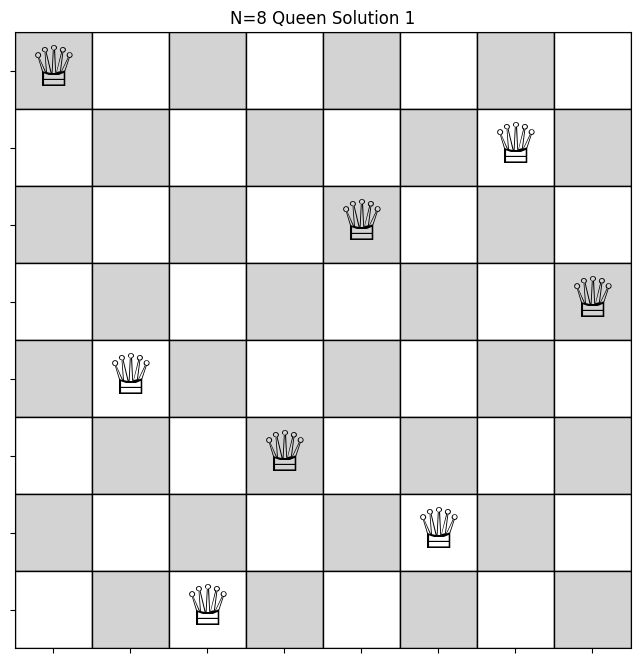

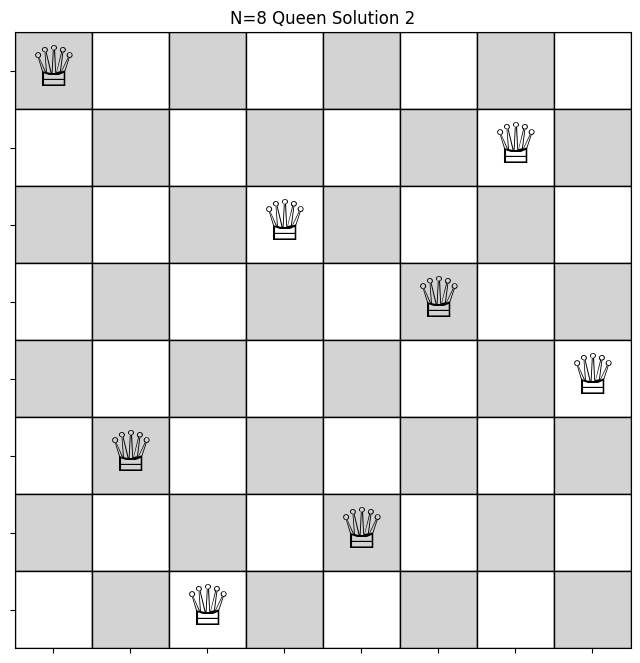

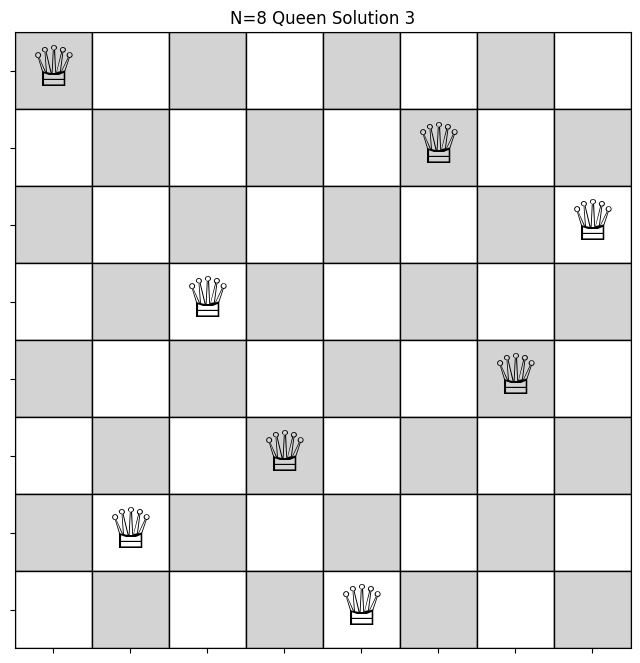

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_board(solution, title="N-Queens Solution"):
    n = len(solution)
    board = np.zeros((n, n))

    fig, ax = plt.subplots(figsize=(n, n))

    # Draw squares
    for i in range(n):
        for j in range(n):
            color = 'lightgray' if (i + j) % 2 == 0 else 'white'
            ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=color, edgecolor='black'))

    # Place queens
    for col, row in enumerate(solution):
        ax.text(col + 0.5, row + 0.5, '♕', fontsize=40, ha='center', va='center', color='black')

    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_xticks(np.arange(0.5, n, 1))
    ax.set_yticks(np.arange(0.5, n, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title)
    plt.gca().invert_yaxis() # Invert y-axis to have (0,0) at top-left
    plt.show()

# Display the first 3 solutions for N=8 using matplotlib
print('\nDisplaying first 3 solutions for N=8 with matplotlib:')
for i, sol in enumerate(sols[:3]):
    plot_board(sol, title=f'N=8 Queen Solution {i+1}')